# Interactive layer stacks

This notebook turns `pyoptics.thin_films` into a small interactive stack
designer: choose the number of layers, their refractive indices and thicknesses,
the polarization, the wavelength range and the angle of incidence, and look at
the reflectance $R$, transmittance $T$ and absorptance $A = 1 - R - T$ as a
function of wavelength and of the angle of incidence. The second part adds
material dispersion with an **Abbe model** (`pyoptics.materials`): a glass is
described by $n_d$ and $V_d$ only, as in a glass catalogue.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$; absorbing media
have $\tilde n = n + i\kappa$ with $\kappa > 0$. Light comes from the embedding
medium (layer 0), passes the layers in the order given and ends in the
semi-infinite substrate.

Note: `thin_films` refers $r$ and $t$ to the tangential field components, so for p
polarization the sign of $r_p$ differs from the convention used in
`interfaces` (see notebook 03). This notebook only uses intensities, which are
the same in both.

**Interactive widgets** need `ipywidgets` (`pip install -e ".[notebooks]"`) and
a running kernel; on GitHub and in other static viewers the widgets do not
render. Every interactive cell is therefore followed by a static figure showing
its default setting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

from pyoptics import thin_films as tf
from pyoptics import materials as mat

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
deg = np.pi/180

## 1. Spectra of a stack

`tf.R_T_A_coeffs()` evaluates one wavelength and one angle at a time. The two
helpers below loop over wavelengths or angles. A layer's refractive index can be
a number or a function `n(wavelength)`, which is how dispersion enters later.
"Unpolarized" is the mean of s and p.

Wavelengths and thicknesses are in nm throughout.

In [2]:
def _eval(n, wavelength):
    return n(wavelength) if callable(n) else n


def RTA(wavelength, angle, layers, n_in=1.0, n_sub=1.52, pol="s"):
    # R, T, A for one wavelength and angle. layers: list of (n, kappa, d),
    # n and kappa may be callables of the wavelength.
    if pol == "unpolarized":
        return 0.5*(np.array(RTA(wavelength, angle, layers, n_in, n_sub, "s"))
                    + np.array(RTA(wavelength, angle, layers, n_in, n_sub, "p")))
    if len(layers) == 0:  # bare substrate: a layer of zero thickness
        layers = [(n_sub, 0.0, 0.0)]
    n = [_eval(l[0], wavelength) for l in layers]
    k = [_eval(l[1], wavelength) for l in layers]
    d = [l[2] for l in layers]
    return np.array(tf.R_T_A_coeffs(angle, n, k, d, _eval(n_in, wavelength), 0.0,
                                    _eval(n_sub, wavelength), 0.0, pol, wavelength))


def spectrum(wavelengths, angle, layers, **kwargs):
    # R, T, A as arrays over the wavelengths
    return np.array([RTA(wl, angle, layers, **kwargs) for wl in wavelengths]).T


def angle_scan(angles, wavelength, layers, **kwargs):
    # R, T, A as arrays over the angles of incidence
    return np.array([RTA(wavelength, a, layers, **kwargs) for a in angles]).T


def quarter_wave(n, wl_0):
    # physical thickness of a quarter wave layer at the design wavelength wl_0
    return wl_0/(4*n)

### Example: anti-reflection coating and Bragg mirror

A single MgF₂ layer ($n = 1.38$) of optical thickness $\lambda_0/4$ on glass
reduces the reflectance from 4.3 % to about 1.3 % at $\lambda_0 = 550$ nm. Eight
periods of alternating quarter wave layers TiO₂/SiO₂ ($n_H = 2.35$, $n_L = 1.46$)
form a Bragg mirror. Its stop band is centred at $\lambda_0$ on a frequency scale,
with half width $\frac{\Delta g}{g_0} = \frac{2}{\pi}\arcsin\frac{n_H - n_L}{n_H + n_L}$
in $g = 1/\lambda$; in wavelength it reaches from $\lambda_0/(1 + \Delta g/g_0)$ to
$\lambda_0/(1 - \Delta g/g_0)$. At oblique incidence the stop band moves to shorter
wavelengths (the phase thickness scales with $\cos\theta$ in each layer) and
becomes narrower for p than for s. The grey band is the stop band of an
infinite stack; with 8 periods R is close to 1 there and drops off more gently
at the edges. In the angle scan at 550 nm, the s band stays wide enough
to keep 550 nm inside at all angles, while the narrower and shifting p band
leaves it above about 55°. (The Brewster angle of the H/L interfaces cannot be
reached from air here: it would need $\sin\theta_0 = n_H n_L/\sqrt{n_H^2 + n_L^2} > 1$.)

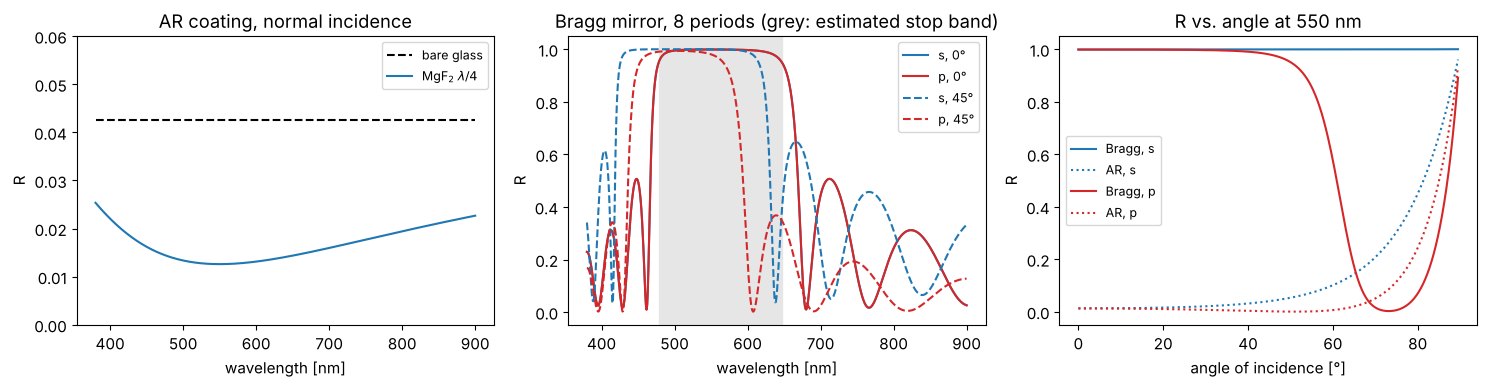

In [3]:
wl_0 = 550.0
nH, nL, n_glass = 2.35, 1.46, 1.52
ar = [(1.38, 0.0, quarter_wave(1.38, wl_0))]
bragg = [(nH, 0.0, quarter_wave(nH, wl_0)), (nL, 0.0, quarter_wave(nL, wl_0))]*8
wl = np.linspace(380, 900, 600)
theta = np.linspace(0, 89.5, 360)*deg

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(wl, spectrum(wl, 0, [], n_sub=n_glass)[0], "k--", label="bare glass")
axes[0].plot(wl, spectrum(wl, 0, ar, n_sub=n_glass)[0], label="MgF$_2$ $\\lambda/4$")
axes[0].set_ylim(0, 0.06); axes[0].set_ylabel("R")
axes[0].set_title("AR coating, normal incidence")
for a, ls in ((0, "-"), (45, "--")):
    for pol, c in (("s", "C0"), ("p", "C3")):
        axes[1].plot(wl, spectrum(wl, a*deg, bragg, n_sub=n_glass, pol=pol)[0],
                     color=c, ls=ls, label=f"{pol}, {a}°")
dg = 2/np.pi*np.arcsin((nH - nL)/(nH + nL))
axes[1].axvspan(wl_0/(1 + dg), wl_0/(1 - dg), color="0.9", zorder=0)
axes[1].set_ylabel("R"); axes[1].set_title("Bragg mirror, 8 periods (grey: estimated stop band)")
for pol, c in (("s", "C0"), ("p", "C3")):
    axes[2].plot(theta/deg, angle_scan(theta, wl_0, bragg, n_sub=n_glass, pol=pol)[0], color=c, label=f"Bragg, {pol}")
    axes[2].plot(theta/deg, angle_scan(theta, wl_0, ar, n_sub=n_glass, pol=pol)[0], color=c, ls=":", label=f"AR, {pol}")
axes[2].set_xlabel("angle of incidence [°]"); axes[2].set_ylabel("R")
axes[2].set_title(f"R vs. angle at {wl_0:.0f} nm")
for ax in axes[:2]:
    ax.set_xlabel("wavelength [nm]")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()

## 2. Interactive stack designer

The number of layers sets how many rows of $(n, \kappa, d)$ input fields are
shown; layer 1 is the one facing the incident light. Changing the layer count
keeps the values already entered and fills new layers with an alternating
quarter wave design at 550 nm. Presets load complete designs.

The left plot shows $R$, $T$ and $A$ versus wavelength at the chosen angle of
incidence; the right one shows them versus the angle of incidence at the chosen
wavelength (the dotted vertical line in the left plot). With
$\kappa > 0$, layers absorb, e.g. a thin metal film ($n \approx 0.06$,
$\kappa \approx 3.6$ for silver at 550 nm).

In [4]:
PRESETS = {
    "AR coating (MgF2)": [(1.38, 0.0, 99.6)],
    "quarter-quarter V coating": [(1.38, 0.0, 99.6), (1.70, 0.0, 80.9)],
    "Bragg mirror (5 periods)": [(2.35, 0.0, 58.5), (1.46, 0.0, 94.2)]*5,
    "Fabry-Perot filter": [(2.35, 0.0, 58.5), (1.46, 0.0, 94.2)]*3 + [(2.35, 0.0, 58.5), (1.46, 0.0, 188.4), (2.35, 0.0, 58.5)]
                          + [(1.46, 0.0, 94.2), (2.35, 0.0, 58.5)]*3,
    "silver film 40 nm": [(0.06, 3.6, 40.0)],
}
MAX_LAYERS = 16


def default_layer(i):
    n = 2.35 if i % 2 == 0 else 1.46
    return (n, 0.0, round(quarter_wave(n, 550.0), 1))


def plot_stack(layers, n_in, n_sub, pol, wl_range, angle_deg, wl_probe, N=500):
    wl = np.linspace(*wl_range, N)
    theta = np.linspace(0, 89.5, 360)*deg
    pols = ["s", "p"] if pol == "s and p" else [pol]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    for p, ls in zip(pols, ["-", "--"]):
        lbl = "" if len(pols) == 1 else f" ({p})"
        R, T, A = spectrum(wl, angle_deg*deg, layers, n_in=n_in, n_sub=n_sub, pol=p)
        Ra, Ta, Aa = angle_scan(theta, wl_probe, layers, n_in=n_in, n_sub=n_sub, pol=p)
        for ax, x, vals in ((axes[0], wl, (R, T, A)), (axes[1], theta/deg, (Ra, Ta, Aa))):
            for v, name, c in zip(vals, "RTA", ("C0", "C1", "C2")):
                if name == "A" and np.max(np.abs(v)) < 1e-6:
                    continue  # no absorption, skip
                ax.plot(x, v, color=c, ls=ls, label=name + lbl)
    axes[0].axvline(wl_probe, color="0.5", ls=":", lw=1)
    axes[0].set_xlabel("wavelength [nm]")
    axes[0].set_title(f"{pol}, angle of incidence {angle_deg:.1f}°")
    axes[1].set_xlabel("angle of incidence [°]")
    axes[1].set_title(f"{pol}, wavelength {wl_probe:.0f} nm")
    total = sum(l[2] for l in layers)
    fig.suptitle(f"{len(layers)} layers, total thickness {total:.0f} nm, "
                 f"$n_\\mathrm{{in}}$ = {n_in}, $n_\\mathrm{{sub}}$ = {n_sub}", y=1.0)
    for ax in axes:
        ax.set_ylim(-0.02, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="best")
    fig.tight_layout()
    plt.show()

In [5]:
class StackDesigner:
    def __init__(self, layers):
        style = {"description_width": "initial"}
        lay = widgets.Layout(width="150px")
        self.rows = [(widgets.BoundedFloatText(value=1.5, min=0.01, max=10, step=0.01, description=f"n{i+1}", layout=lay),
                      widgets.BoundedFloatText(value=0.0, min=0, max=20, step=0.01, description=f"κ{i+1}", layout=lay),
                      widgets.BoundedFloatText(value=100., min=0, max=1e5, step=1, description=f"d{i+1} [nm]", layout=lay, style=style))
                     for i in range(MAX_LAYERS)]
        self.n_layers = widgets.IntSlider(value=len(layers), min=0, max=MAX_LAYERS, description="layers")
        self.preset = widgets.Dropdown(options=["(custom)"] + list(PRESETS), description="preset")
        self.n_in = widgets.BoundedFloatText(value=1.0, min=0.1, max=5, step=0.01, description="n embedding", style=style, layout=widgets.Layout(width="180px"))
        self.n_sub = widgets.BoundedFloatText(value=1.52, min=0.1, max=5, step=0.01, description="n substrate", style=style, layout=widgets.Layout(width="180px"))
        self.pol = widgets.ToggleButtons(options=["s", "p", "s and p", "unpolarized"], value="s and p", description="polarization")
        self.wl_range = widgets.FloatRangeSlider(value=(380, 900), min=200, max=2000, step=10, description="λ range [nm]", style=style, continuous_update=False, layout=widgets.Layout(width="450px"))
        self.angle = widgets.FloatSlider(value=0, min=0, max=89, step=0.5, description="angle [°]", continuous_update=False)
        self.wl_probe = widgets.FloatSlider(value=550, min=200, max=2000, step=5, description="λ for angle scan [nm]", style=style, continuous_update=False, layout=widgets.Layout(width="450px"))
        self.layer_box = widgets.VBox()
        self.out = widgets.Output()
        self._busy = False
        self.set_layers(layers)
        self.n_layers.observe(self._on_count, "value")
        self.preset.observe(self._on_preset, "value")
        for w in [self.n_in, self.n_sub, self.pol, self.wl_range, self.angle, self.wl_probe] + [w for r in self.rows for w in r]:
            w.observe(self._on_change, "value")
        self._show_rows()
        self.update()

    def layers(self):
        return [tuple(w.value for w in row) for row in self.rows[:self.n_layers.value]]

    def set_layers(self, layers):
        self._busy = True
        for row, vals in zip(self.rows, layers):
            for w, v in zip(row, vals):
                w.value = v
        self.n_layers.value = len(layers)
        self._busy = False

    def _show_rows(self):
        self.layer_box.children = [widgets.HBox(r) for r in self.rows[:self.n_layers.value]]

    def _on_count(self, change):
        if not self._busy:
            self._busy = True
            for i in range(change["old"], change["new"]):  # fill newly added layers
                for w, v in zip(self.rows[i], default_layer(i)):
                    w.value = v
            self.preset.value = "(custom)"
            self._busy = False
        self._show_rows()
        self.update()

    def _on_preset(self, change):
        if change["new"] in PRESETS:
            self.set_layers(PRESETS[change["new"]])
            self._show_rows()
            self.update()

    def _on_change(self, change):
        if not self._busy:
            self.update()

    def update(self):
        self.out.clear_output(wait=True)
        with self.out:
            plot_stack(self.layers(), self.n_in.value, self.n_sub.value, self.pol.value,
                       self.wl_range.value, self.angle.value, self.wl_probe.value)

    def widget(self):
        controls = widgets.VBox([widgets.HBox([self.preset, self.n_layers]),
                                 widgets.HBox([self.n_in, self.n_sub]), self.pol,
                                 widgets.HBox([self.wl_range, self.angle]), self.wl_probe])
        return widgets.VBox([widgets.HBox([controls, self.layer_box]), self.out])


designer = StackDesigner(PRESETS["Fabry-Perot filter"])
display(designer.widget())

**Static view of the default setting** (Fabry-Perot filter: two quarter wave
mirrors around a half wave SiO₂ spacer, s and p, normal incidence). The narrow
transmission peak at 550 nm sits in the middle of the mirrors' stop band. In the
angle scan at 550 nm, the peak tunes away from the probe wavelength: above about
10° the filter blocks 550 nm, and p tolerates tilt slightly better than s.

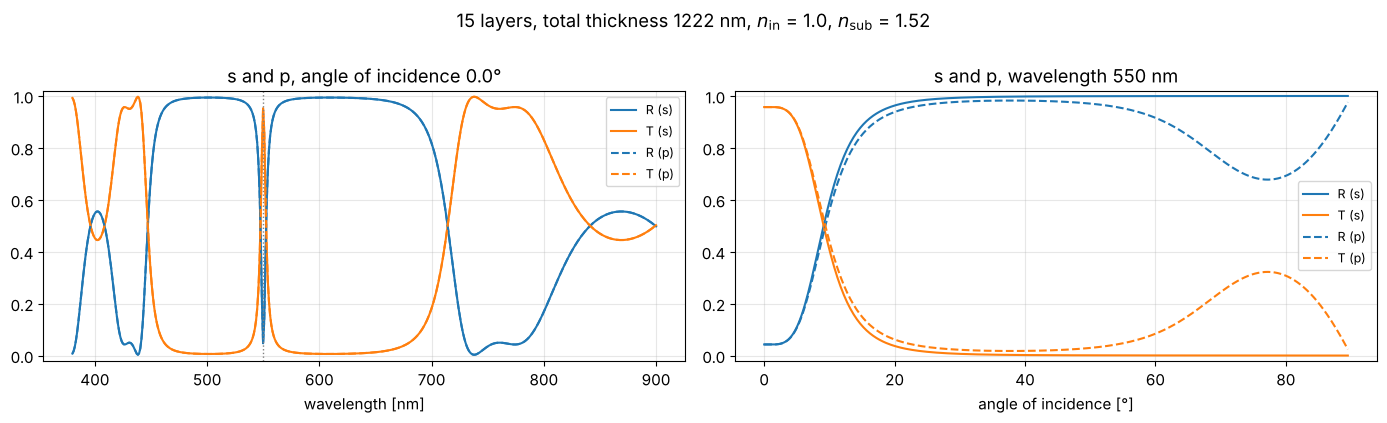

In [6]:
plot_stack(PRESETS["Fabry-Perot filter"], 1.0, 1.52, "s and p", (380, 900), 0.0, 550.0)

The same function, at 30° for a 40 nm silver film: even a 40 nm film
reflects more than 90 %, transmits a few percent (more in the red) and absorbs
about 2 %. Unlike for dielectric layers, the absorptance $A$ is not zero.

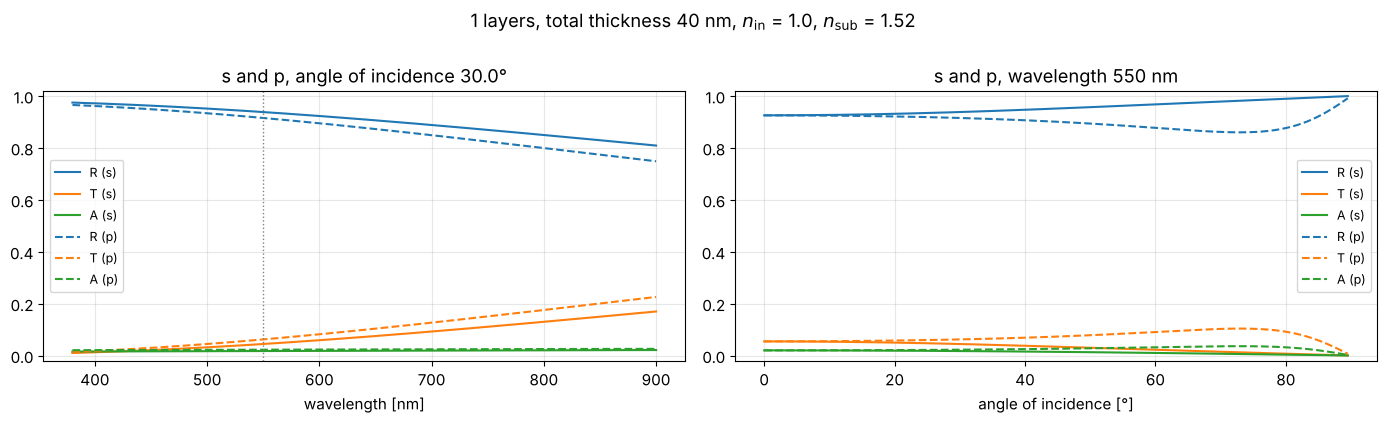

In [7]:
plot_stack(PRESETS["silver film 40 nm"], 1.0, 1.52, "s and p", (380, 900), 30.0, 550.0)

(The constant $n$, $\kappa$ used for silver are a rough value at 550 nm; real
metals are strongly dispersive. Enter tabulated data via callables, as shown for
glasses in the next section.)

## 3. Dispersion with the Abbe model

A glass catalogue characterizes a glass by its refractive index $n_d$ at the helium
d line ($\lambda_d = 587.6$ nm) and its **Abbe number**

$$V_d = \frac{n_d - 1}{n_F - n_C}$$

with the hydrogen lines F (486.1 nm) and C (656.3 nm). Small $V_d$ means strong
dispersion (flint glasses), large $V_d$ weak dispersion (crown glasses).
`pyoptics.materials.abbe_dispersion()` turns $(n_d, V_d)$ into a dispersion curve
with the two-term Cauchy formula

$$n(\lambda) = A + \frac{B}{\lambda^2}, \qquad
B = \frac{n_d - 1}{V_d}\left(\frac{1}{\lambda_F^2} - \frac{1}{\lambda_C^2}\right)^{-1}, \qquad
A = n_d - \frac{B}{\lambda_d^2},$$

which reproduces $n_d$ and $V_d$ exactly. For N-BK7 it agrees with Schott's
Sellmeier formula to a few $10^{-4}$ in the visible, but it misses the
absorption bands, so it gets worse in the UV and IR.

N-BK7 model: n_d = 1.5168, V_d = 64.17


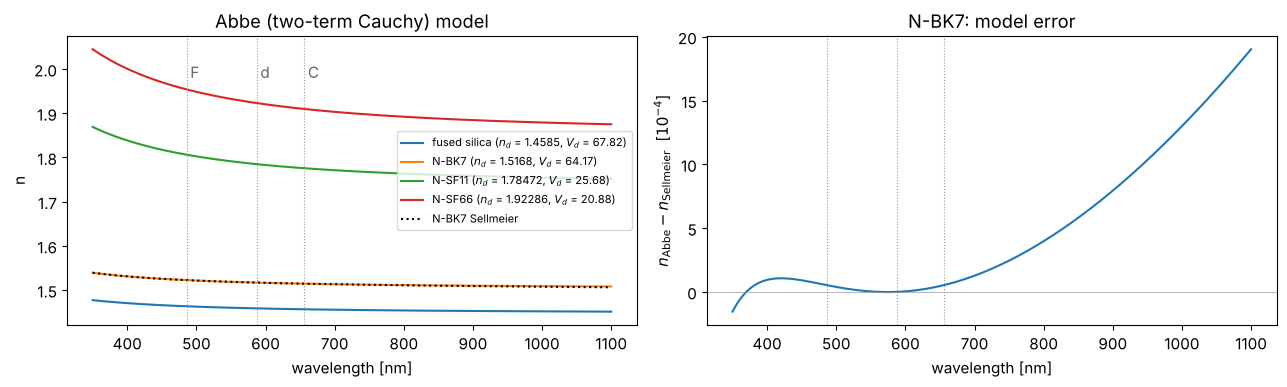

In [8]:
glasses = {"fused silica": (1.4585, 67.82), "N-BK7": (1.5168, 64.17),
           "N-SF11": (1.78472, 25.68), "N-SF66": (1.92286, 20.88)}

def n_bk7_sellmeier(wl_nm):
    B = (1.03961212, 0.231792344, 1.01046945)
    C = (0.00600069867, 0.0200179144, 103.560653)
    wl2 = (wl_nm/1000)**2
    return np.sqrt(1 + sum(b*wl2/(wl2 - c) for b, c in zip(B, C)))

wl = np.linspace(350, 1100, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (n_d, V_d) in glasses.items():
    axes[0].plot(wl, mat.abbe_dispersion(wl, n_d, V_d), label=f"{name} ($n_d$ = {n_d}, $V_d$ = {V_d})")
axes[0].plot(wl, n_bk7_sellmeier(wl), "k:", label="N-BK7 Sellmeier")
for line, lw in ((mat.LAMBDA_F, "F"), (mat.LAMBDA_d, "d"), (mat.LAMBDA_C, "C")):
    for ax in axes:
        ax.axvline(line, color="0.6", lw=0.8, ls=":")
    axes[0].text(line + 5, 1.98, lw, color="0.4")
axes[0].set_ylabel("n"); axes[0].set_title("Abbe (two-term Cauchy) model")
axes[0].legend(fontsize=8, loc="center right")
dn = mat.abbe_dispersion(wl, 1.5168, 64.17) - n_bk7_sellmeier(wl)
axes[1].plot(wl, dn*1e4)
axes[1].axhline(0, color="0.6", lw=0.5)
axes[1].set_ylabel("$n_\\mathrm{Abbe} - n_\\mathrm{Sellmeier}$  [$10^{-4}$]")
axes[1].set_title("N-BK7: model error")
for ax in axes:
    ax.set_xlabel("wavelength [nm]")
fig.tight_layout()

n_d, n_F, n_C = mat.abbe_dispersion([mat.LAMBDA_d, mat.LAMBDA_F, mat.LAMBDA_C], 1.5168, 64.17)
print(f"N-BK7 model: n_d = {n_d:.4f}, V_d = {mat.abbe_number(n_d, n_F, n_C):.2f}")

### Dispersive layers in a stack

Dispersion enters the stack by passing functions `n(wavelength)` instead of
numbers. Two examples:

- **Bragg mirror** from a dense flint (N-SF66, high index) and fused silica (low
  index), both quarter wave at $\lambda_0$ = 1200 nm. A quarter wave stack has a
  further stop band at $\lambda_0/3$ = 400 nm. With constant indices (frozen at
  $\lambda_0$) it sits exactly there; with dispersion both indices are larger in
  the blue, the optical thicknesses grow, and the band moves to longer
  wavelengths and widens, since the index contrast grows as well. Near
  $\lambda_0$ the two models agree. (Beyond 1 µm the two-term model is only
  rough, see above, but it serves for illustration.)
- **AR coating on a flint substrate:** the reflectance of bare N-SF11 rises
  towards the blue simply because $n$ does; a MgF₂ quarter wave layer cannot
  compensate that equally at all wavelengths. With the coating the effect is
  smaller, the dispersive substrate mostly raises R in the blue.

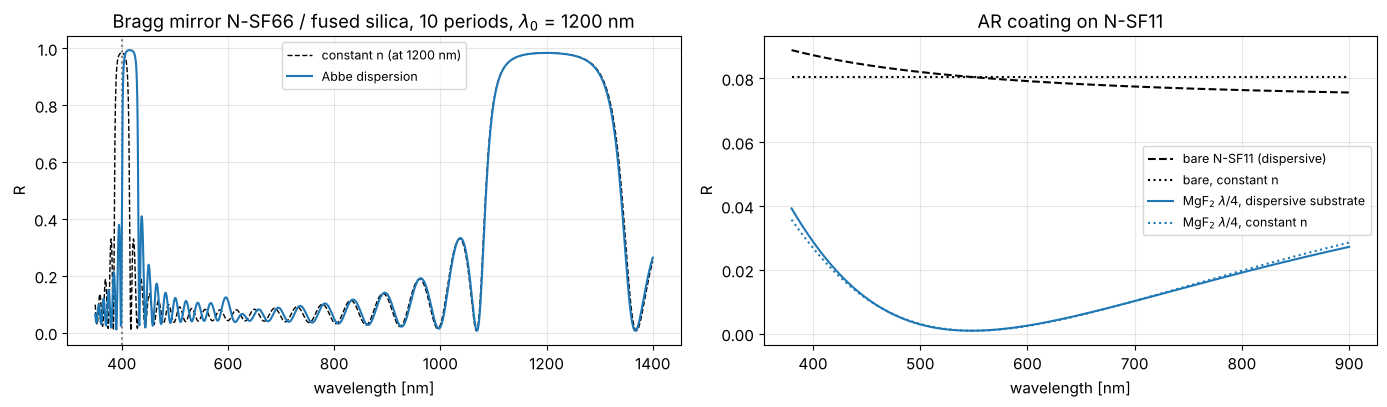

In [9]:
wl_0 = 1200.0
n_H = lambda wl: mat.abbe_dispersion(wl, *glasses["N-SF66"])
n_L = lambda wl: mat.abbe_dispersion(wl, *glasses["fused silica"])
d_H, d_L = quarter_wave(n_H(wl_0), wl_0), quarter_wave(n_L(wl_0), wl_0)
mirror_disp = [(n_H, 0.0, d_H), (n_L, 0.0, d_L)]*10
mirror_const = [(n_H(wl_0), 0.0, d_H), (n_L(wl_0), 0.0, d_L)]*10
n_sub_bk7 = lambda wl: mat.abbe_dispersion(wl, *glasses["N-BK7"])

wl = np.linspace(350, 1400, 1500)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(wl, spectrum(wl, 0, mirror_const, n_sub=n_sub_bk7)[0], "k--", lw=1, label=f"constant n (at {wl_0:.0f} nm)")
axes[0].axvline(wl_0/3, color="0.5", ls=":")
axes[0].plot(wl, spectrum(wl, 0, mirror_disp, n_sub=n_sub_bk7)[0], label="Abbe dispersion")
axes[0].set_title(f"Bragg mirror N-SF66 / fused silica, 10 periods, $\\lambda_0$ = {wl_0:.0f} nm")
axes[0].set_ylabel("R")

n_sf11 = lambda wl: mat.abbe_dispersion(wl, *glasses["N-SF11"])
wl_0 = 550.0
wl = np.linspace(380, 900, 400)
n_mgf2 = 1.38
ar = [(n_mgf2, 0.0, quarter_wave(n_mgf2, wl_0))]
axes[1].plot(wl, spectrum(wl, 0, [], n_sub=n_sf11)[0], "k--", label="bare N-SF11 (dispersive)")
axes[1].plot(wl, spectrum(wl, 0, [], n_sub=n_sf11(wl_0))[0], "k:", label="bare, constant n")
axes[1].plot(wl, spectrum(wl, 0, ar, n_sub=n_sf11)[0], label="MgF$_2$ $\\lambda/4$, dispersive substrate")
axes[1].plot(wl, spectrum(wl, 0, ar, n_sub=n_sf11(wl_0))[0], ":", color="C0", label="MgF$_2$ $\\lambda/4$, constant n")
axes[1].set_title("AR coating on N-SF11"); axes[1].set_ylabel("R")
for ax in axes:
    ax.set_xlabel("wavelength [nm]"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()

### Interactive: Bragg mirror from two Abbe glasses

Choose $n_d$ and $V_d$ for the high and low index material, the number of
periods and the design wavelength $\lambda_0$ (both layers are quarter wave at
$\lambda_0$). The upper plot compares the reflectance with the dispersion free
case (indices frozen at $\lambda_0$), the lower one shows both $n(\lambda)$ curves.
Setting $V_d$ to its maximum (1000) practically switches dispersion off.

In [10]:
def plot_abbe_mirror(nd_H, Vd_H, nd_L, Vd_L, periods, wl_0, angle_deg, pol, wl_range):
    nH = lambda wl: mat.abbe_dispersion(wl, nd_H, Vd_H)
    nL = lambda wl: mat.abbe_dispersion(wl, nd_L, Vd_L)
    dH, dL = quarter_wave(nH(wl_0), wl_0), quarter_wave(nL(wl_0), wl_0)
    disp = [(nH, 0.0, dH), (nL, 0.0, dL)]*periods
    const = [(nH(wl_0), 0.0, dH), (nL(wl_0), 0.0, dL)]*periods
    wl = np.linspace(*wl_range, 800)
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(wl, spectrum(wl, angle_deg*deg, const, n_sub=1.52, pol=pol)[0], "k--", lw=1, label="constant n")
    axes[0].plot(wl, spectrum(wl, angle_deg*deg, disp, n_sub=1.52, pol=pol)[0], label="Abbe dispersion")
    axes[0].set_ylabel("R"); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
    axes[0].set_title(f"{periods} periods, quarter wave at {wl_0:.0f} nm, {pol}, {angle_deg:.1f}°, substrate n = 1.52")
    axes[1].plot(wl, nH(wl), color="C3", label=f"H: $n_d$ = {nd_H:.3f}, $V_d$ = {Vd_H:.1f}")
    axes[1].plot(wl, nL(wl), color="C0", label=f"L: $n_d$ = {nd_L:.3f}, $V_d$ = {Vd_L:.1f}")
    axes[1].axvline(wl_0, color="0.5", ls=":")
    axes[0].axvline(wl_0/3, color="0.5", ls=":")
    axes[1].set_ylabel("n"); axes[1].set_xlabel("wavelength [nm]"); axes[1].legend(fontsize=9)
    fig.tight_layout()
    plt.show()

s = {"continuous_update": False, "style": {"description_width": "initial"}}
abbe_controls = dict(
    nd_H=widgets.FloatSlider(value=1.92286, min=1.3, max=2.5, step=0.005, description="H: n_d", readout_format=".3f", **s),
    Vd_H=widgets.FloatSlider(value=20.88, min=10, max=1000, step=0.5, description="H: V_d", **s),
    nd_L=widgets.FloatSlider(value=1.4585, min=1.3, max=2.5, step=0.005, description="L: n_d", readout_format=".3f", **s),
    Vd_L=widgets.FloatSlider(value=67.82, min=10, max=1000, step=0.5, description="L: V_d", **s),
    periods=widgets.IntSlider(value=10, min=1, max=30, description="periods", **s),
    wl_0=widgets.FloatSlider(value=1200, min=300, max=2000, step=5, description="λ0 [nm]", **s),
    angle_deg=widgets.FloatSlider(value=0, min=0, max=89, step=0.5, description="angle [°]", **s),
    pol=widgets.ToggleButtons(options=["s", "p", "unpolarized"], value="s", description="polarization"),
    wl_range=widgets.FloatRangeSlider(value=(350, 1400), min=200, max=2500, step=10, description="λ range [nm]", **s),
)
c = abbe_controls
display(widgets.VBox([
    widgets.HBox([widgets.VBox([c["nd_H"], c["Vd_H"], c["periods"], c["angle_deg"]]),
                  widgets.VBox([c["nd_L"], c["Vd_L"], c["wl_0"], c["wl_range"]])]),
    c["pol"],
    widgets.interactive_output(plot_abbe_mirror, abbe_controls),
]))

**Static view of the default setting** (N-SF66 / fused silica, 10 periods,
$\lambda_0$ = 1200 nm, normal incidence; dotted line: $\lambda_0/3$):

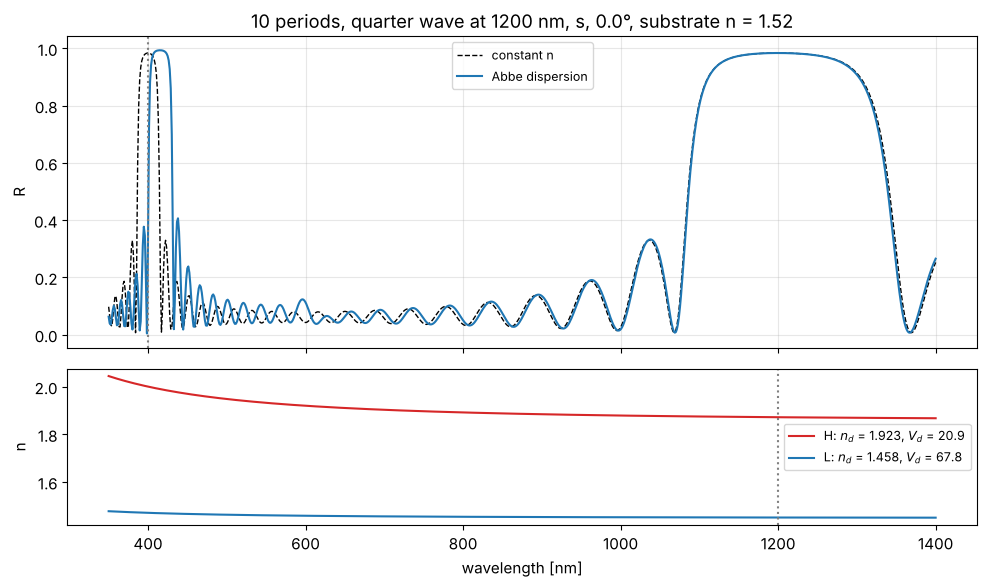

In [11]:
plot_abbe_mirror(1.92286, 20.88, 1.4585, 67.82, 10, 1200.0, 0.0, "s", (350, 1400))

Things to try: raise $V_d$ of the high index material to 1000 and the
dispersive and constant curves coincide; lower it to 10 and the third order
stop band near $\lambda_0/3$ moves markedly. Tilting the stack moves all stop bands to
shorter wavelengths, for p polarization they also become narrower.